# RetailPulse — Customer Inactivity Prediction (v2)

**Question.** Using the preceding six calendar months of a customer's transactions, can we predict better than the current module whether the customer makes **no purchase in the next three calendar months**?

**What is unchanged.** Target (`Inactive = 1` ⇔ no purchase in the next 3 calendar months), 6-month observation window, 3-month horizon, eligibility (customer purchased in the window), the 16 monthly snapshots (May 2010 – Aug 2011) and the cleaned data. Labels are never modified. Customer segmentation is not touched.

**What is new.**
1. A feature builder shared by training and inference (`src/features/inactivity_features.py`) and an inference module (`src/models/inactivity_inference.py`).
2. **Rolling-origin validation** (expanding window, labels must have matured before each origin) instead of one 3-snapshot validation split.
3. **Experiment A** — feature groups computed *strictly inside the 6-month window*, tested by ablation.
4. **Experiment B** — a clearly separate experiment that extends the look-back to 12 months (6-month window + the 6 months before it). It changes the information available, so it is kept apart from A.
5. Chronological hyper-parameter tuning for seven model families, and a confirmatory evaluation on snapshots that no earlier experiment evaluated.

**Evidence discipline.** Every number below is computed when the notebook runs. Selection rules are written *before* the results they govern. Interpretation text only describes what the executed output shows.

### Data roles (fixed before any modelling)
| Role | Origins (snapshot months) | Used for |
|---|---|---|
| Development folds | Dec 2010 – May 2011 (6) | diagnostics, ablation, tuning, model selection |
| Confirmatory block | Jun, Jul 2011 | evaluated once, after all choices are frozen; never evaluated in earlier work |
| Previously inspected holdout | Aug 2011 | evaluated once, after freezing; **not pristine** (inspected in earlier work) |

*Design freeze:* no development decision uses a label from a prediction window that extends past 31 Aug 2011 (the last development fold's labels end exactly there).

In [1]:
# 1. Setup
from pathlib import Path
import sys, json, hashlib, platform, time, warnings, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier)
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name.lower() == "notebooks" else CURRENT_DIR
sys.path.insert(0, str(PROJECT_ROOT))

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_transactions.csv"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "inactivity"
FIGURE_DIR = PROJECT_ROOT / "docs" / "inactivity" / "figures"
DOC_DIR = PROJECT_ROOT / "docs" / "inactivity"
for d in (ARTIFACT_DIR, FIGURE_DIR, DOC_DIR):
    d.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}. Run from the RetailPulse root or its notebooks/ folder.")

from src.features.inactivity_features import (
    OBSERVATION_MONTHS, PREDICTION_MONTHS, FEATURE_GROUPS, IN_WINDOW_GROUPS,
    EXTENDED_LOOKBACK_GROUPS, snapshot_windows, prepare_transactions,
    build_snapshot_features, build_labels, fit_derived_params,
    add_derived_features, columns_for)
from src.models.inactivity_inference import (load_bundle, score_snapshot,
                                             assign_risk_band, validate_feature_frame)

# Optional boosted-tree libraries: a family is skipped (and reported) if its library is missing.
OPTIONAL = {}
for lib in ("xgboost", "lightgbm", "catboost"):
    try:
        OPTIONAL[lib] = importlib.import_module(lib)
    except ImportError:
        print(f"[skipped] {lib} not installed")

print("Project root:", PROJECT_ROOT)
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__, *[f"| {k} {v.__version__}" for k, v in OPTIONAL.items()])

Project root: /tmp/rp
python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | sklearn 1.8.0 | xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10


## 1. Data and integrity checks
The cleaned file already separates ordinary purchases from cancellations and returns, so every row is a positive-quantity, positive-price purchase line. The checks below confirm that (and that the two source sheets were not double-counted in their December 2010 overlap) rather than assuming it.

In [2]:
# 2. Load cleaned transactions and verify integrity
raw = pd.read_csv(DATA_PATH, parse_dates=["InvoiceDate"], dtype={"Invoice": "string", "StockCode": "string"})

checks = {
    "all quantities > 0": bool((raw["Quantity"] > 0).all()),
    "all prices > 0": bool((raw["Price"] > 0).all()),
    "all transaction values > 0": bool((raw["TransactionValue"] > 0).all()),
    "no cancellation invoices ('C' prefix)": not raw["Invoice"].astype(str).str.upper().str.startswith("C").any(),
    "no exact duplicate rows (all columns)": not raw.duplicated().any(),
    "no invoice shared by two customers": not (raw.dropna(subset=["Customer ID"])
                                               .groupby("Invoice")["Customer ID"].nunique() > 1).any(),
    "no invoice present in both source sheets": raw.groupby("Invoice")["SourceSheet"].nunique().max() == 1,
}
print("Rows:", f"{len(raw):,}", "| rows without Customer ID:", f"{raw['Customer ID'].isna().sum():,}",
      f"({raw['Customer ID'].isna().mean():.1%} of rows, {raw.loc[raw['Customer ID'].isna(), 'TransactionValue'].sum() / raw['TransactionValue'].sum():.1%} of revenue)")
for name, ok in checks.items():
    print(("PASS " if ok else "FAIL ") + name)
assert all(checks.values()), "Data integrity check failed"

tx = prepare_transactions(raw)                       # identified customers only, sorted by time
DATA_START = tx["InvoiceDate"].min().normalize().replace(day=1)
print("\nIdentified-customer lines:", f"{len(tx):,}", "| customers:", f"{tx['Customer ID'].nunique():,}")
print("Date range:", tx["InvoiceDate"].min(), "->", tx["InvoiceDate"].max())

Rows: 1,007,913 | rows without Customer ID: 228,488 (22.7% of rows, 15.1% of revenue)
PASS all quantities > 0
PASS all prices > 0
PASS all transaction values > 0
PASS no cancellation invoices ('C' prefix)
PASS no exact duplicate rows (all columns)
PASS no invoice shared by two customers
PASS no invoice present in both source sheets

Identified-customer lines: 779,425 | customers: 5,878
Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


## 2. Snapshots, eligibility and labels (unchanged definition)
For each month-end snapshot: eligible customers = those with ≥ 1 purchase in the 6 calendar months ending at the snapshot; `Inactive = 1` if they have no purchase in the following 3 calendar months. Anonymous purchases (no Customer ID) cannot be attributed, so "inactive" means *no identified purchase*.

In [3]:
# 3. Build the customer-snapshot table (features + labels)
SNAPSHOT_PERIODS = pd.period_range("2010-05", "2011-08", freq="M")
assert max(snapshot_windows(p.end_time)["prediction_end"] for p in SNAPSHOT_PERIODS) <= tx["InvoiceDate"].max(), \
    "Prediction windows extend beyond the available data"

parts = []
for period in SNAPSHOT_PERIODS:
    feats = build_snapshot_features(tx, period.end_time, data_start=DATA_START)
    feats["Inactive"] = build_labels(tx, period.end_time, feats["Customer ID"])
    parts.append(feats)
TABLE = pd.concat(parts, ignore_index=True)
TABLE["SnapPeriod"] = TABLE["Snapshot"].dt.to_period("M")

assert not TABLE.duplicated(["Customer ID", "Snapshot"]).any(), "duplicate customer-snapshot rows"
assert set(TABLE["Inactive"].unique()) <= {0, 1}
assert TABLE["Recency"].between(0, 183).all()

summary = TABLE.groupby("SnapPeriod").agg(Customers=("Customer ID", "size"),
                                          InactivityRate=("Inactive", "mean"))
print("Customer-snapshot rows:", f"{len(TABLE):,}", "| unique customers:", f"{TABLE['Customer ID'].nunique():,}",
      "| snapshots:", TABLE['SnapPeriod'].nunique(), "| overall inactivity:", f"{TABLE['Inactive'].mean():.3f}")
display(summary.T.round(3))

Customer-snapshot rows: 48,394 | unique customers: 5,249 | snapshots: 16 | overall inactivity: 0.508


SnapPeriod,2010-05,2010-06,2010-07,2010-08,2010-09,2010-10,2010-11,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08
Customers,2703.000,2757.000,2832.000,2868.00,2924.000,3222.000,3497.000,3428.000,3386.000,3358.000,3321.000,3060.00,2718.000,2724.000,2783.000,2813.000
InactivityRate,0.503,0.485,0.425,0.38,0.423,0.507,0.621,0.624,0.606,0.576,0.559,0.52,0.504,0.469,0.438,0.395


### Leakage guards (executed tests)
1. **Future-invariance:** features for a snapshot must be identical when every transaction after that snapshot is deleted.
2. **Window-invariance (Experiment A):** the in-window feature groups must be identical when every transaction *before* the observation window is also deleted — this proves Experiment A uses only the 6-month window.
3. **Label maturity:** asserted for every fold when the folds are created (section 3).

In [4]:
# 4. Leakage guard tests on three snapshots (early, middle, late)
# CADENCE columns are derived afterwards from Frequency, ActiveSpanDays and Recency (tested here) plus training-only parameters
a_cols = [c for c in columns_for(IN_WINDOW_GROUPS) if c not in FEATURE_GROUPS["CADENCE"]]
for period in [pd.Period("2010-10", "M"), pd.Period("2011-03", "M"), pd.Period("2011-08", "M")]:
    snap = period.end_time
    w = snapshot_windows(snap)
    full = build_snapshot_features(tx, snap, data_start=DATA_START).set_index("Customer ID")
    # (1) delete the future
    no_future = tx[tx["InvoiceDate"] <= snap]
    f1 = build_snapshot_features(no_future, snap, data_start=DATA_START).set_index("Customer ID")
    pd.testing.assert_frame_equal(full.sort_index(), f1.sort_index().reindex(columns=full.columns), check_dtype=False)
    # (2) delete everything outside the observation window -> in-window features unchanged
    window_only = tx[(tx["InvoiceDate"] >= w["observation_start"]) & (tx["InvoiceDate"] <= snap)]
    f2 = build_snapshot_features(window_only, snap, data_start=DATA_START).set_index("Customer ID")
    pd.testing.assert_frame_equal(full[a_cols].sort_index(), f2[a_cols].sort_index(), check_dtype=False)
    print(f"{period}: future-invariance PASS | in-window-only invariance PASS ({len(full):,} customers, {len(a_cols)} features)")

2010-10: future-invariance PASS | in-window-only invariance PASS (3,222 customers, 37 features)


2011-03: future-invariance PASS | in-window-only invariance PASS (3,321 customers, 37 features)


2011-08: future-invariance PASS | in-window-only invariance PASS (2,813 customers, 37 features)


## 3. Evaluation protocol: rolling-origin folds
For an **origin** month *t* the model may train only on snapshots whose 3-month label window has fully ended by *t*; it is tested on the snapshot at *t*. Training windows expand over time. This mirrors deployment (at *t* you only know outcomes that have already happened) and replaces the single three-month validation split, whose three snapshots share customers and a season.

Derived features that need population parameters (the cadence prior) are fitted on each fold's training rows only. Imputation and scaling live inside the model pipeline and are likewise fitted on training rows only.

In [5]:
# 5. Fold definitions, helpers, estimator factory
DEV_ORIGINS = [pd.Period(x, "M") for x in ["2010-12", "2011-01", "2011-02", "2011-03", "2011-04", "2011-05"]]
CONFIRM_ORIGINS = [pd.Period(x, "M") for x in ["2011-06", "2011-07"]]
HOLDOUT_ORIGIN = pd.Period("2011-08", "M")
LOCKED_ORIGINS = CONFIRM_ORIGINS + [HOLDOUT_ORIGIN]

FOLD_CACHE = {}
def get_fold(origin):
    key = str(origin)
    if key not in FOLD_CACHE:
        train = TABLE[TABLE["SnapPeriod"] + PREDICTION_MONTHS <= origin]
        test = TABLE[TABLE["SnapPeriod"] == origin]
        assert len(train) and len(test)
        # label maturity: the last training label window ends no later than the origin's observation end
        assert (train["SnapPeriod"].max() + PREDICTION_MONTHS).end_time <= test["Snapshot"].iloc[0]
        params = fit_derived_params(train)                    # training rows only
        FOLD_CACHE[key] = (add_derived_features(train, params), add_derived_features(test, params), params)
    return FOLD_CACHE[key]

# design freeze: development labels end by the holdout snapshot's observation end
assert max(snapshot_windows(o.end_time)["prediction_end"] for o in DEV_ORIGINS) <= HOLDOUT_ORIGIN.end_time
# Origins whose training data contains at least one snapshot with an observable prior window (Experiment B)
DEV_B_ORIGINS = [o for o in DEV_ORIGINS if get_fold(o)[0]["PriorWindowInvoices"].notna().any()]

fold_info = pd.DataFrame([{
    "Origin": str(o), "Role": ("development" if o in DEV_ORIGINS else "confirmatory" if o in CONFIRM_ORIGINS else "previously inspected holdout"),
    "Train snapshots": get_fold(o)[0]["SnapPeriod"].nunique(), "Train rows": len(get_fold(o)[0]),
    "Test rows": len(get_fold(o)[1]), "Test inactivity": get_fold(o)[1]["Inactive"].mean(),
    "Train snapshots with prior window": get_fold(o)[0].loc[get_fold(o)[0]["PriorWindowInvoices"].notna(), "SnapPeriod"].nunique(),
    "Same calendar month in training": (o - 12) in set(get_fold(o)[0]["SnapPeriod"])}
    for o in DEV_ORIGINS + LOCKED_ORIGINS])
display(fold_info.round(3))
print("Origins used to test Experiment B on the development data:", [str(o) for o in DEV_B_ORIGINS])


# ---------- estimators ----------
LOG1P_COLUMNS = ["Frequency", "Monetary", "AverageOrderValue", "TotalQuantity", "UniqueProducts", "Recency",
                 "InvoicesLast30Days", "InvoicesLast60Days", "InvoicesLast90Days",
                 "SpendLast30Days", "SpendLast60Days", "SpendLast90Days",
                 "InvoicesMonth0", "InvoicesMonth1", "InvoicesMonth2", "InvoicesMonth3", "InvoicesMonth4", "InvoicesMonth5",
                 "MeanPurchaseGapDays", "StdPurchaseGapDays", "LastPurchaseGapDays", "ActiveSpanDays",
                 "SmoothedGapDays", "RecencyOverCadence", "DaysSinceFirstInWindow",
                 "AverageQuantityPerInvoice", "AvgLinesPerInvoice", "PriorWindowInvoices", "PriorWindowSpend",
                 "PriorWindowActiveMonths", "PriorWindowRecencyDays", "ObservedTenureDays"]

def make_estimator(family, params, cols):
    p = dict(params)
    if family == "LR":
        log_cols = [c for c in cols if c in LOG1P_COLUMNS]
        pre = ColumnTransformer([("log1p", FunctionTransformer(np.log1p, validate=False), log_cols)], remainder="passthrough")
        return Pipeline([("pre", pre), ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                         ("scale", StandardScaler()),
                         ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE, **p))])
    if family == "RF":
        return Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1, **p))])
    if family == "GB":
        return Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE, **p))])
    if family == "HGB":
        return HistGradientBoostingClassifier(random_state=RANDOM_STATE, **p)
    if family == "XGB":
        return OPTIONAL["xgboost"].XGBClassifier(subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, n_jobs=1,
                                                 random_state=RANDOM_STATE, verbosity=0, **p)
    if family == "LGBM":
        return OPTIONAL["lightgbm"].LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
                                                   n_jobs=1, random_state=RANDOM_STATE, verbose=-1, **p)
    if family == "CatBoost":
        return OPTIONAL["catboost"].CatBoostClassifier(thread_count=1, random_seed=RANDOM_STATE, verbose=0,
                                                       allow_writing_files=False, **p)
    raise ValueError(family)

DEFAULT_PARAMS = {
    "LR": dict(C=1.0),
    "RF": dict(n_estimators=200, min_samples_leaf=50, max_features=0.5),
    "GB": dict(n_estimators=150, learning_rate=0.05, max_depth=2, min_samples_leaf=20, subsample=0.8),  # project's existing config
    "HGB": dict(max_iter=200, learning_rate=0.05, max_leaf_nodes=8, min_samples_leaf=100, l2_regularization=1.0),
    "XGB": dict(n_estimators=250, learning_rate=0.03, max_depth=3, min_child_weight=20),
    "LGBM": dict(n_estimators=250, learning_rate=0.03, num_leaves=8, min_child_samples=50),
    "CatBoost": dict(iterations=300, learning_rate=0.05, depth=4, l2_leaf_reg=5),
}
FAMILIES = [f for f in ["LR", "RF", "GB", "HGB", "XGB", "LGBM", "CatBoost"]
            if f in ("LR", "RF", "GB", "HGB") or {"XGB": "xgboost", "LGBM": "lightgbm", "CatBoost": "catboost"}[f] in OPTIONAL]


# ---------- evaluation helpers ----------
def score_metrics(y, p):
    return {"ROC_AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p), "Prevalence": float(np.mean(y)), "N": len(y)}

def run_rolling(cols, factory, origins, train_filter=None, train_auc=False):
    rows, preds = [], []
    for o in origins:
        train, test, _ = get_fold(o)
        if train_filter is not None:
            train = train_filter(train)
        model = factory(cols)
        model.fit(train[cols], train["Inactive"])
        p = model.predict_proba(test[cols])[:, 1]
        row = {"Origin": str(o), **score_metrics(test["Inactive"].values, p)}
        if train_auc:
            row["Train_ROC_AUC"] = roc_auc_score(train["Inactive"], model.predict_proba(train[cols])[:, 1])
        rows.append(row)
        preds.append(pd.DataFrame({"Origin": str(o), "Customer ID": test["Customer ID"].values,
                                   "y": test["Inactive"].values, "p": p}))
    return pd.DataFrame(rows), pd.concat(preds, ignore_index=True)

def _prep_boot(pred):
    codes, uniques = pd.factorize(pred["Customer ID"])
    groups = {o: np.where(pred["Origin"].values == o)[0] for o in pred["Origin"].unique()}
    return codes, len(uniques), groups

def paired_bootstrap(pred_ref, pred_new, n_boot=300, seed=0, metric=roc_auc_score):
    """Customer-clustered bootstrap of the mean-over-origins metric difference (new - reference).
    Customers are resampled with all their rows in every origin, so correlation between
    snapshots of the same customer is preserved."""
    assert (pred_ref[["Origin", "Customer ID", "y"]].values == pred_new[["Origin", "Customer ID", "y"]].values).all()
    codes, n, groups = _prep_boot(pred_ref)
    y, pr, pn = pred_ref["y"].values, pred_ref["p"].values, pred_new["p"].values
    point = np.mean([metric(y[i], pn[i]) - metric(y[i], pr[i]) for i in groups.values()])
    rng = np.random.default_rng(seed)
    deltas = np.empty(n_boot)
    for b in range(n_boot):
        w = np.bincount(rng.integers(0, n, n), minlength=n)[codes]
        d = []
        for i in groups.values():
            keep = i[w[i] > 0]
            d.append(metric(y[keep], pn[keep], sample_weight=w[keep]) - metric(y[keep], pr[keep], sample_weight=w[keep]))
        deltas[b] = np.mean(d)
    lo, hi = np.percentile(deltas, [2.5, 97.5])
    return float(point), float(lo), float(hi)

def bootstrap_ci(pred, metric=roc_auc_score, n_boot=500, seed=0):
    """Customer-clustered CI for the mean-over-origins value of one model."""
    codes, n, groups = _prep_boot(pred)
    y, p = pred["y"].values, pred["p"].values
    point = np.mean([metric(y[i], p[i]) for i in groups.values()])
    rng = np.random.default_rng(seed)
    vals = np.empty(n_boot)
    for b in range(n_boot):
        w = np.bincount(rng.integers(0, n, n), minlength=n)[codes]
        vals[b] = np.mean([metric(y[i[w[i] > 0]], p[i[w[i] > 0]], sample_weight=w[i[w[i] > 0]]) for i in groups.values()])
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(point), float(lo), float(hi)

def brier_w(y, p, sample_weight=None):
    return brier_score_loss(y, p, sample_weight=sample_weight)

def calibration_stats(y, p, bins=10):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit, y)
    edges = np.quantile(p, np.linspace(0, 1, bins + 1))
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, bins - 1)
    ece = sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean()) for b in range(bins) if (idx == b).any())
    return {"Mean_pred": p.mean(), "Observed": float(np.mean(y)), "Cal_intercept": float(lr.intercept_[0]),
            "Cal_slope": float(lr.coef_[0, 0]), "ECE": float(ece)}

def operating_metrics(y, p, threshold=None, top_share=None):
    y = np.asarray(y); p = np.asarray(p)
    if top_share is not None:
        threshold = np.quantile(p, 1 - top_share)
        pred = (p >= threshold).astype(int)
    else:
        pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Threshold": float(threshold), "Flagged": float(pred.mean()), "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

def expected_auc(p):
    """Expected ROC-AUC of ranking by p if labels were Bernoulli(p) (i.e. p perfectly calibrated)."""
    p = np.sort(np.asarray(p, float))
    above = np.cumsum(p[::-1])[::-1] - p                      # sum of p_i for scores above j
    num = np.sum((1 - p) * above)
    den = p.sum() * (1 - p).sum() - np.sum(p * (1 - p))
    return num / den

BUCKETS = [("1 invoice", lambda f: f == 1), ("2-3 invoices", lambda f: f.between(2, 3)), ("4+ invoices", lambda f: f >= 4)]
FREQ_LOOKUP = TABLE.assign(Origin=TABLE["SnapPeriod"].astype(str))[["Origin", "Customer ID", "Frequency"]]
def stratified_auc(pred):
    m = pred.merge(FREQ_LOOKUP, on=["Origin", "Customer ID"], how="left", validate="one_to_one")
    out = {}
    for name, rule in BUCKETS:
        aucs = [roc_auc_score(g["y"], g["p"]) for _, g in m[rule(m["Frequency"])].groupby("Origin")
                if g["y"].nunique() == 2]
        out[name] = float(np.mean(aucs))
    out["share_of_rows"] = {name: float(rule(m["Frequency"]).mean()) for name, rule in BUCKETS}
    return out
print("Model families available:", FAMILIES)

,Origin,Role,Train snapshots,Train rows,Test rows,Test inactivity,Train snapshots with prior window,Same calendar month in training
0,2010-12,development,5,14084,3428,0.624,0,False
1,2011-01,development,6,17306,3386,0.606,0,False
2,2011-02,development,7,20803,3358,0.576,1,False
3,2011-03,development,8,24231,3321,0.559,2,False
4,2011-04,development,9,27617,3060,0.520,3,False
5,2011-05,development,10,30975,2718,0.504,4,True
6,2011-06,confirmatory,11,34296,2724,0.469,5,True
7,2011-07,confirmatory,12,37356,2783,0.438,6,True
8,2011-08,previously inspected holdout,13,40074,2813,0.395,7,True


Origins used to test Experiment B on the development data: ['2011-02', '2011-03', '2011-04', '2011-05']
Model families available: ['LR', 'RF', 'GB', 'HGB', 'XGB', 'LGBM', 'CatBoost']


## 4. The "before" models, reproduced
The existing module is reproduced here from the same data so that "before" and "after" come from one executed code path:

* **GB-7** — Gradient Boosting on the original seven features (the project's baseline).
* **GB-17** — the repaired notebook's selected model: the seven plus ten extra features. Note that its `ObservedTenureDays` uses transactions from *before* the observation window, so it is a look-back-extending feature, not an in-window one.

First on the previous fixed split (train ≤ Oct 2010, validation Feb–Apr 2011, holdout Aug 2011), then under rolling-origin validation. Previously recorded artifact values are printed next to the recomputed ones when the artifact exists (traceability only; nothing is asserted against them).

In [6]:
# 6. Reproduce the previous results (fixed split) and the baseline under rolling-origin validation
BASE_COLS = columns_for(["BASE"])
GB17_COLS = BASE_COLS + ["InvoicesLast30Days", "InvoicesLast60Days", "InvoicesLast90Days",
                         "SpendLast30Days", "SpendLast60Days", "SpendLast90Days",
                         "MeanPurchaseGapDays", "StdPurchaseGapDays", "ObservedTenureDays", "AverageQuantityPerInvoice"]
PREV = {"GB-7": ("GB", BASE_COLS), "GB-17 (repaired notebook)": ("GB", GB17_COLS)}

fx_train = TABLE[TABLE["SnapPeriod"] <= pd.Period("2010-10", "M")]
fx_val = TABLE[TABLE["SnapPeriod"].isin([pd.Period(x, "M") for x in ["2011-02", "2011-03", "2011-04"]])]
fx_hold = TABLE[TABLE["SnapPeriod"] == HOLDOUT_ORIGIN]
assert (fx_train["SnapPeriod"].max() + PREDICTION_MONTHS).end_time <= fx_val["Snapshot"].min()
assert (fx_val["SnapPeriod"].max() + PREDICTION_MONTHS).end_time <= fx_hold["Snapshot"].min()

rows = []
for name, (fam, cols) in PREV.items():
    m = make_estimator(fam, DEFAULT_PARAMS[fam], cols).fit(fx_train[cols], fx_train["Inactive"])
    for split, df_ in (("validation (Feb-Apr 2011, pooled)", fx_val), ("previously inspected holdout (Aug 2011)", fx_hold)):
        rows.append({"Model": name, "Split": split, **score_metrics(df_["Inactive"].values, m.predict_proba(df_[cols])[:, 1])})
fixed_split_before = pd.DataFrame(rows)
display(fixed_split_before.round(4))

prev_csv = ARTIFACT_DIR / "inactivity_validation_comparison.csv"
if prev_csv.exists():
    prev = pd.read_csv(prev_csv)
    print("Previously saved validation values (from the earlier notebook's artifact, for traceability):")
    display(prev[prev["Model"].isin(["Gradient Boosting \u2014 original", "Gradient Boosting \u2014 extended"])][["Model", "ROC-AUC", "PR-AUC", "Brier score"]].round(4))

# Baselines under rolling-origin validation (same training data for every model)
before_dev = {}; before_pred_dev = {}
for name, (fam, cols) in PREV.items():
    before_dev[name], before_pred_dev[name] = run_rolling(cols, lambda c, fam=fam: make_estimator(fam, DEFAULT_PARAMS[fam], c), DEV_ORIGINS)
print("\nRolling-origin development folds (ROC-AUC):")
display(pd.DataFrame({k: v.set_index("Origin")["ROC_AUC"] for k, v in before_dev.items()}).assign().round(4)
        .pipe(lambda d: pd.concat([d, d.mean().to_frame("MEAN").T])))

,Model,Split,ROC_AUC,PR_AUC,Brier,Prevalence,N
0,GB-7,"validation (Feb-Apr 2011, pooled)",0.7450,0.7423,0.2069,0.5525,9739
1,GB-7,previously inspected holdout (Aug 2011),0.7418,0.6093,0.2016,0.3953,2813
2,GB-17 (repaired notebook),"validation (Feb-Apr 2011, pooled)",0.7595,0.7621,0.2183,0.5525,9739
3,GB-17 (repaired notebook),previously inspected holdout (Aug 2011),0.7468,0.6283,0.1972,0.3953,2813


Previously saved validation values (from the earlier notebook's artifact, for traceability):


,Model,ROC-AUC,PR-AUC,Brier score
0,Gradient Boosting — extended,0.7595,0.7621,0.2183
2,Gradient Boosting — original,0.7450,0.7423,0.2069



Rolling-origin development folds (ROC-AUC):


,GB-7,GB-17 (repaired notebook)
2010-12,0.769600,0.787000
2011-01,0.752800,0.769900
2011-02,0.750900,0.757400
2011-03,0.743700,0.746700
2011-04,0.748000,0.753800
2011-05,0.759100,0.764600
MEAN,0.754017,0.763233


## 5. Why does performance plateau? Diagnostics on the development folds
Each test below addresses one candidate bottleneck from the brief. They use development folds only and the existing 7-feature baseline.

In [7]:
# 7. Prevalence shift, seasonality coverage and trivial baselines
# (a) Does a trivial rule explain the headline F1? (flag everybody = F1 of 2p/(1+p))
gb7_pred = before_pred_dev["GB-7"]
trivial = []
for o in DEV_ORIGINS:
    g = gb7_pred[gb7_pred["Origin"] == str(o)]
    pf = g["y"].mean()
    trivial.append({"Origin": str(o), "Prevalence": pf, "Flag-all F1": 2 * pf / (1 + pf),
                    "GB-7 F1 @0.5": f1_score(g["y"], (g["p"] >= 0.5).astype(int))})
trivial = pd.DataFrame(trivial)
print("F1 on the positive class is not informative at these prevalences:")
display(trivial.round(3).pipe(lambda d: pd.concat([d, d.drop(columns='Origin').mean().to_frame('MEAN').T.assign(Origin='MEAN')[d.columns]])))

# (b) Single-feature rankers with a-priori orientation (no fitting) vs the baseline model
orient = {"Frequency": -1, "Monetary": -1, "ActiveMonths": -1, "Recency": +1}
sf = []
for o in DEV_ORIGINS:
    te = get_fold(o)[1]
    sf.append({"Origin": str(o), **{f"{k} only": roc_auc_score(te["Inactive"], s * te[k]) for k, s in orient.items()},
               "GB-7 (7 features)": before_dev["GB-7"].set_index("Origin").loc[str(o), "ROC_AUC"]})
sf = pd.DataFrame(sf).set_index("Origin")
print("ROC-AUC of single features vs the full baseline model (dev folds):")
display(pd.concat([sf, sf.mean().to_frame("MEAN").T]).round(4))

# (c) Seasonality: can month-of-year effects be learned and validated?
seas = fold_info[["Origin", "Test inactivity", "Same calendar month in training"]]
print("Base rate varies strongly with the calendar, but a same-month training example exists only for:",
      list(seas.loc[seas["Same calendar month in training"], "Origin"]))

F1 on the positive class is not informative at these prevalences:


,Origin,Prevalence,Flag-all F1,GB-7 F1 @0.5
0,2010-12,0.624000,0.769,0.673000
1,2011-01,0.606000,0.755,0.681000
2,2011-02,0.576000,0.731,0.718000
3,2011-03,0.559000,0.717,0.743000
4,2011-04,0.520000,0.684,0.740000
5,2011-05,0.504000,0.670,0.733000
MEAN,MEAN,0.564833,0.721,0.714667


ROC-AUC of single features vs the full baseline model (dev folds):


,Frequency only,Monetary only,ActiveMonths only,Recency only,GB-7 (7 features)
2010-12,0.7506,0.7489,0.7505,0.6763,0.7696
2011-01,0.7351,0.7346,0.7323,0.6775,0.7528
2011-02,0.7310,0.7293,0.7256,0.6887,0.7509
2011-03,0.7206,0.7199,0.7137,0.6957,0.7437
2011-04,0.7142,0.7241,0.7118,0.6925,0.7480
2011-05,0.7306,0.7317,0.7259,0.6680,0.7591
MEAN,0.7303,0.7314,0.7266,0.6831,0.7540


Base rate varies strongly with the calendar, but a same-month training example exists only for: ['2011-05', '2011-06', '2011-07', '2011-08']


In [8]:
# 8. Customer heterogeneity and a label-noise ceiling (baseline model, development folds)
strat = stratified_auc(gb7_pred)
share = strat.pop("share_of_rows")
print("ROC-AUC by number of invoices in the observation window (mean over dev origins):")
display(pd.DataFrame({"AUC": strat, "Share of customer-snapshots": share}).round(3))

# Self-consistency ceiling: if the model's probabilities were perfectly calibrated, how well could
# it rank?  Calibrate each origin's predictions with a 2-parameter logistic map (diagnostic only).
rows = []
for o in DEV_ORIGINS:
    g = gb7_pred[gb7_pred["Origin"] == str(o)]
    lp = np.log(np.clip(g["p"], 1e-6, 1 - 1e-6) / (1 - np.clip(g["p"], 1e-6, 1 - 1e-6))).values.reshape(-1, 1)
    cal = LogisticRegression(C=1e6, max_iter=1000).fit(lp, g["y"]).predict_proba(lp)[:, 1]
    rows.append({"Origin": str(o), "Realised AUC": roc_auc_score(g["y"], g["p"]), "Expected AUC if calibrated": expected_auc(cal)})
ceil = pd.DataFrame(rows).set_index("Origin")
display(pd.concat([ceil, ceil.mean().to_frame("MEAN").T]).round(4))

ROC-AUC by number of invoices in the observation window (mean over dev origins):


,AUC,Share of customer-snapshots
1 invoice,0.583,0.456
2-3 invoices,0.618,0.328
4+ invoices,0.753,0.216


,Realised AUC,Expected AUC if calibrated
2010-12,0.7696,0.7732
2011-01,0.7528,0.7600
2011-02,0.7509,0.7585
2011-03,0.7437,0.7488
2011-04,0.7480,0.7477
2011-05,0.7591,0.7599
MEAN,0.7540,0.7580


In [9]:
# 9. Under/over-fitting by model family, and a learning curve (development folds)
fit_rows = []
for fam in ["LR", "GB", "HGB", "RF"]:
    res, _ = run_rolling(BASE_COLS, lambda c, fam=fam: make_estimator(fam, DEFAULT_PARAMS[fam], c), DEV_ORIGINS, train_auc=True)
    fit_rows.append({"Family": fam, "Train ROC-AUC": res["Train_ROC_AUC"].mean(), "Test ROC-AUC": res["ROC_AUC"].mean()})
fit_df = pd.DataFrame(fit_rows).set_index("Family"); fit_df["Gap"] = fit_df["Train ROC-AUC"] - fit_df["Test ROC-AUC"]
print("Train vs out-of-time ROC-AUC (7 features, default configs, mean of dev folds):")
display(fit_df.round(4))

# Learning curve on the last development fold: resample CUSTOMERS from the training set
origin = DEV_ORIGINS[-1]
train, test, _ = get_fold(origin)
customers = train["Customer ID"].unique()
rng = np.random.default_rng(RANDOM_STATE)
lc = []
for frac in [0.1, 0.25, 0.5, 0.75, 1.0]:
    aucs = []
    for rep in range(1 if frac == 1.0 else 5):
        chosen = rng.choice(customers, size=int(frac * len(customers)), replace=False)
        sub = train[train["Customer ID"].isin(chosen)]
        m = make_estimator("HGB", DEFAULT_PARAMS["HGB"], BASE_COLS).fit(sub[BASE_COLS], sub["Inactive"])
        aucs.append(roc_auc_score(test["Inactive"], m.predict_proba(test[BASE_COLS])[:, 1]))
    lc.append({"Training customers": int(frac * len(customers)), "Rows": int(len(sub)), "AUC mean": np.mean(aucs), "AUC sd": np.std(aucs)})
display(pd.DataFrame(lc).round(4))

Train vs out-of-time ROC-AUC (7 features, default configs, mean of dev folds):


,Train ROC-AUC,Test ROC-AUC,Gap
Family,,,
LR,0.7342,0.7515,-0.0173
GB,0.7447,0.7540,-0.0093
HGB,0.7546,0.7523,0.0023
RF,0.7983,0.7491,0.0492


,Training customers,Rows,AUC mean,AUC sd
0,453,3140,0.7310,0.0051
1,1134,7651,0.7439,0.0011
2,2268,15483,0.7504,0.0034
3,3402,23118,0.7550,0.0010
4,4537,30975,0.7594,0.0000


### What the diagnostics show — evidence versus hypothesis
The numbers above are the evidence; this list separates what they establish from what remains a hypothesis. (Magnitudes are in the printed tables.)

**Supported by the executed output**
* **Headline F1/precision/recall are prevalence artefacts.** At these prevalences, flagging every customer scores about as well on F1 as the model does at a 0.5 threshold (and better in the high-prevalence early folds), and prevalence swings widely across origins. ROC-AUC (prevalence-free), Brier score and capacity-based metrics are the meaningful ones.
* **One engagement dimension carries most of the signal.** Single features (frequency, monetary, active months) reach most of the seven-feature model's AUC; the model adds a modest margin on top.
* **Model flexibility is not the bottleneck.** Linear and boosted models give nearly the same AUC, and train and out-of-time AUC are close for the low-variance models. Random Forest is the exception: its large train/test gap reflects overfitting of near-duplicate customer rows, not extra signal.
* **More history still helps.** AUC keeps rising as the number of training customers grows and has not plateaued at the full training size, so the amount of data is a real limit.
* **Predictability is very uneven across customers.** Customers with a single invoice are ranked far worse than customers with four or more, and single-invoice customers are the largest group.
* **The calibrated-probability ceiling is close to the realised AUC**, i.e. the model's own uncertainty is about as large as its performance implies.
* **Seasonality cannot be validated with this history.** The calendar base rate moves a lot, yet a same-month training example exists for only one development origin (May 2011) and for the locked origins.

**Hypotheses (not established by these tests)**
* The remaining error is largely irreducible purchase-timing randomness for the information in a 6-month window. The ceiling test is consistent with this but is not proof; it holds only if the calibrated probabilities are well specified.
* Label noise from anonymous (no Customer ID) purchases adds to it, but its size cannot be measured here.
* Information from *before* the observation window (customer history) could separate the large single-invoice group — this is tested separately as Experiment B, because it changes the look-back.

## 6. Experiment A — feature groups computed strictly inside the 6-month window
Candidate groups (all computed only from the observation window; verified by the window-invariance test above):
`RECENT` 30/60/90-day counts and spend · `MONTHLY` invoices per calendar month · `TREND` first-half vs second-half frequency, spend, AOV and basket-size change · `TIMING` inter-purchase gap statistics · `CADENCE` recency relative to the customer's typical gap (shrunk toward the population gap, fitted on training rows only; single-invoice customers fall back to the population gap) · `TENURE` days since first in-window purchase · `BASKET` basket size, product diversity, repeat-SKU share, order-value concentration · `COUNTRY` UK flag.

**Pre-registered decision rule.** Ablation uses two families with fixed default hyper-parameters (Logistic Regression and Histogram Gradient Boosting) so a feature group cannot win by being tuned. A group is *kept* only if, in at least one family, adding it to `BASE` raises the mean fold ROC-AUC by **≥ 0.002** and the customer-clustered bootstrap 95% CI of that difference **excludes 0**. The kept groups are then verified jointly against `BASE`; if the joint set does not itself satisfy the rule, `BASE` is retained.

In [10]:
# 10. Experiment A ablation (development folds)
ABL_FAMILIES = ["LR", "HGB"]
MIN_GAIN = 0.002
def fit_cols(groups, family, origins, cache={}):
    key = (tuple(groups), family, tuple(map(str, origins)))
    if key not in cache:
        cols = columns_for(groups)
        cache[key] = run_rolling(cols, lambda c: make_estimator(family, DEFAULT_PARAMS[family], c), origins)
    return cache[key]

def ablate(base_groups, candidates, origins, n_boot=300):
    rows = []
    for fam in ABL_FAMILIES:
        ref_res, ref_pred = fit_cols(base_groups, fam, origins)
        full_groups = base_groups + candidates
        full_res, full_pred = fit_cols(full_groups, fam, origins)
        d, lo, hi = paired_bootstrap(ref_pred, full_pred, n_boot)
        rows.append({"Family": fam, "Group": "ALL candidates", "Mode": "add all to base", "Base AUC": ref_res["ROC_AUC"].mean(),
                     "dAUC": d, "CI_lo": lo, "CI_hi": hi})
        for g in candidates:
            add_res, add_pred = fit_cols(base_groups + [g], fam, origins)
            d, lo, hi = paired_bootstrap(ref_pred, add_pred, n_boot)
            rows.append({"Family": fam, "Group": g, "Mode": "add one to base", "Base AUC": ref_res["ROC_AUC"].mean(), "dAUC": d, "CI_lo": lo, "CI_hi": hi})
            if len(candidates) > 1:
                rest = [x for x in candidates if x != g]
                lo_res, lo_pred = fit_cols(base_groups + rest, fam, origins)
                d, lo, hi = paired_bootstrap(lo_pred, full_pred, n_boot)
                rows.append({"Family": fam, "Group": g, "Mode": "leave one out of full", "Base AUC": full_res["ROC_AUC"].mean(), "dAUC": d, "CI_lo": lo, "CI_hi": hi})
    out = pd.DataFrame(rows)
    out["Meets rule"] = (out["dAUC"] >= MIN_GAIN) & (out["CI_lo"] > 0)
    return out

A_CANDIDATES = [g for g in IN_WINDOW_GROUPS if g != "BASE"]
t0 = time.time()
ablation_A = ablate(["BASE"], A_CANDIDATES, DEV_ORIGINS)
print(f"Experiment A ablation on {len(DEV_ORIGINS)} development folds ({time.time()-t0:.0f}s). dAUC = change in mean fold ROC-AUC.")
display(ablation_A.round(4))

Experiment A ablation on 6 development folds (288s). dAUC = change in mean fold ROC-AUC.


,Family,Group,Mode,Base AUC,dAUC,CI_lo,CI_hi,Meets rule
0,LR,ALL candidates,add all to base,0.7515,-0.0018,-0.0046,0.0010,False
1,LR,RECENT,add one to base,0.7515,-0.0008,-0.0016,0.0001,False
2,LR,RECENT,leave one out of full,0.7497,-0.0003,-0.0008,0.0001,False
3,LR,MONTHLY,add one to base,0.7515,-0.0001,-0.0014,0.0012,False
4,LR,MONTHLY,leave one out of full,0.7497,-0.0011,-0.0020,-0.0001,False
5,LR,TREND,add one to base,0.7515,-0.0010,-0.0019,-0.0001,False
6,LR,TREND,leave one out of full,0.7497,0.0001,-0.0007,0.0009,False
7,LR,TIMING,add one to base,0.7515,-0.0001,-0.0012,0.0013,False
8,LR,TIMING,leave one out of full,0.7497,-0.0006,-0.0015,0.0004,False
9,LR,CADENCE,add one to base,0.7515,0.0020,0.0010,0.0029,False


In [11]:
# 11. Apply the pre-registered rule for Experiment A
add_one = ablation_A[ablation_A["Mode"] == "add one to base"]
kept = sorted(add_one.loc[add_one["Meets rule"], "Group"].unique(), key=A_CANDIDATES.index)
print("Groups meeting the rule individually:", kept or "none")

A_GROUPS = ["BASE"]
if kept:
    joint = {}
    for fam in ABL_FAMILIES:
        _, ref_pred = fit_cols(["BASE"], fam, DEV_ORIGINS)
        _, new_pred = fit_cols(["BASE"] + kept, fam, DEV_ORIGINS)
        joint[fam] = paired_bootstrap(ref_pred, new_pred, 300)
    print("Joint check (kept groups vs BASE):", {k: tuple(round(x, 4) for x in v) for k, v in joint.items()})
    if any(d >= MIN_GAIN and lo > 0 for d, lo, hi in joint.values()):
        A_GROUPS = ["BASE"] + kept
A_COLS = columns_for(A_GROUPS)
print("\nExperiment A final feature groups:", A_GROUPS, "->", len(A_COLS), "features")
if A_GROUPS == ["BASE"]:
    print("VERDICT A: no in-window feature group produced a reliable improvement; the original seven features are retained.")
else:
    print("VERDICT A: in-window groups retained:", kept)

# Context: all in-window groups together versus BASE (not a selection rule, just the total effect)
for fam in ABL_FAMILIES:
    r = ablation_A[(ablation_A["Family"] == fam) & (ablation_A["Group"] == "ALL candidates")].iloc[0]
    print(f"All in-window groups vs BASE, {fam}: dAUC={r['dAUC']:+.4f}  95% CI [{r['CI_lo']:+.4f}, {r['CI_hi']:+.4f}]")

Groups meeting the rule individually: none

Experiment A final feature groups: ['BASE'] -> 7 features
VERDICT A: no in-window feature group produced a reliable improvement; the original seven features are retained.
All in-window groups vs BASE, LR: dAUC=-0.0018  95% CI [-0.0046, +0.0010]
All in-window groups vs BASE, HGB: dAUC=-0.0006  95% CI [-0.0033, +0.0016]


## 7. Experiment B — extending the look-back (separate experiment)
**This changes what information the model sees, so it is not part of Experiment A.** The features use transactions strictly *before the snapshot* but partly *before the observation window*:

* `PRIOR` — number of invoices in the 6 months before the window (a 12-month look-back in total).
* `PRIOR_EXTRA` — prior-window spend, active months, recency, and 12-month trend.
* `LIFETIME` — days since the customer was first seen in the data (the repaired notebook's `ObservedTenureDays`).

**Constraint of this dataset.** The data start in Dec 2009, so the prior window is observable only for snapshots from Nov 2010 onward. For earlier snapshots the features are *missing* (not zero). Tree models handle this natively; the linear model imputes with the training median plus a missing-indicator. Consequently, the early development origins (whose training data contain no snapshot with an observable prior window) cannot benefit by construction; Experiment B is judged on the origins listed in section 3, with the same pre-registered rule as Experiment A.

Sensitivity checks follow: training only on snapshots whose prior window is observable (complete-case), and where in the customer base the gain arises.

In [12]:
# 12. Experiment B ablation (origins whose training data contain observable prior windows)
B_CANDIDATES = EXTENDED_LOOKBACK_GROUPS
t0 = time.time()
ablation_B = ablate(A_GROUPS, B_CANDIDATES, DEV_B_ORIGINS)
print(f"Experiment B ablation on {len(DEV_B_ORIGINS)} folds ({time.time()-t0:.0f}s), base = {A_GROUPS}:")
display(ablation_B.round(4))

add_one_B = ablation_B[ablation_B["Mode"] == "add one to base"]
kept_B = sorted(add_one_B.loc[add_one_B["Meets rule"], "Group"].unique(), key=B_CANDIDATES.index)
B_GROUPS = A_GROUPS + kept_B
B_COLS = columns_for(B_GROUPS)
print("\nGroups meeting the rule:", kept_B or "none", "| Experiment B feature groups:", B_GROUPS, "->", len(B_COLS), "features")

Experiment B ablation on 4 folds (76s), base = ['BASE']:


,Family,Group,Mode,Base AUC,dAUC,CI_lo,CI_hi,Meets rule
0,LR,ALL candidates,add all to base,0.7476,0.0209,0.0144,0.0262,True
1,LR,PRIOR,add one to base,0.7476,0.0238,0.0183,0.0290,True
2,LR,PRIOR,leave one out of full,0.7685,-0.0002,-0.0006,0.0002,False
3,LR,PRIOR_EXTRA,add one to base,0.7476,0.0241,0.0185,0.0294,True
4,LR,PRIOR_EXTRA,leave one out of full,0.7685,-0.0002,-0.0020,0.0017,False
5,LR,LIFETIME,add one to base,0.7476,0.0027,0.0012,0.0040,True
6,LR,LIFETIME,leave one out of full,0.7685,-0.0029,-0.0040,-0.0019,False
7,HGB,ALL candidates,add all to base,0.7491,0.0310,0.0232,0.0385,True
8,HGB,PRIOR,add one to base,0.7491,0.0317,0.0248,0.0380,True
9,HGB,PRIOR,leave one out of full,0.7802,-0.0003,-0.0012,0.0005,False



Groups meeting the rule: ['PRIOR', 'PRIOR_EXTRA', 'LIFETIME'] | Experiment B feature groups: ['BASE', 'PRIOR', 'PRIOR_EXTRA', 'LIFETIME'] -> 13 features


In [13]:
# 13. Experiment B sensitivity and where the gain comes from
if kept_B:
    # (i) complete-case training: only snapshots whose prior window is observable
    cc = lambda tr: tr[tr["PriorWindowInvoices"].notna()]
    rows = []
    for fam in ABL_FAMILIES:
        mixed, _ = run_rolling(B_COLS, lambda c, f=fam: make_estimator(f, DEFAULT_PARAMS[f], c), DEV_B_ORIGINS)
        comp, _ = run_rolling(B_COLS, lambda c, f=fam: make_estimator(f, DEFAULT_PARAMS[f], c), DEV_B_ORIGINS, train_filter=cc)
        a_only, _ = run_rolling(A_COLS, lambda c, f=fam: make_estimator(f, DEFAULT_PARAMS[f], c), DEV_B_ORIGINS)
        rows.append({"Family": fam, "A features": a_only["ROC_AUC"].mean(), "B, all matured snapshots": mixed["ROC_AUC"].mean(),
                     "B, complete-case training": comp["ROC_AUC"].mean()})
    print("Mean ROC-AUC on the Experiment-B origins:")
    display(pd.DataFrame(rows).set_index("Family").round(4))

    # (ii) which customers gain?  Stratify by invoices in the window, A vs B (HGB defaults)
    _, pa = fit_cols(A_GROUPS, "HGB", DEV_B_ORIGINS)
    _, pb = fit_cols(B_GROUPS, "HGB", DEV_B_ORIGINS)
    sa, sb = stratified_auc(pa), stratified_auc(pb)
    share = sa.pop("share_of_rows"); sb.pop("share_of_rows")
    display(pd.DataFrame({"A (in-window)": sa, "B (12-month look-back)": sb, "Share of rows": share}).assign(Gain=lambda d: d["B (12-month look-back)"] - d["A (in-window)"]).round(3))

    # (iii) raw relationship: inactivity rate by prior-window activity within invoice-count buckets
    te_all = TABLE[TABLE["SnapPeriod"].isin(DEV_B_ORIGINS) & TABLE["PriorWindowInvoices"].notna()].copy()
    te_all["Window invoices"] = pd.cut(te_all["Frequency"], [0, 1, 3, np.inf], labels=["1", "2-3", "4+"])
    te_all["Prior-window invoices"] = pd.cut(te_all["PriorWindowInvoices"], [-1, 0, 2, np.inf], labels=["0", "1-2", "3+"])
    display(te_all.pivot_table(index="Window invoices", columns="Prior-window invoices", values="Inactive", aggfunc="mean", observed=True).round(3)
            .style.set_caption("Inactivity rate"))
else:
    print("No Experiment-B group met the rule; skipping sensitivity checks.")

Mean ROC-AUC on the Experiment-B origins:


,A features,"B, all matured snapshots","B, complete-case training"
Family,,,
LR,0.7476,0.7685,0.7779
HGB,0.7491,0.7802,0.7788


,A (in-window),B (12-month look-back),Share of rows,Gain
1 invoice,0.584,0.672,0.472,0.088
2-3 invoices,0.614,0.669,0.321,0.055
4+ invoices,0.768,0.783,0.207,0.014


Prior-window invoices,0,1-2,3+
Window invoices,,,
1,0.796000,0.677000,0.513000
2-3,0.632000,0.538000,0.347000
4+,0.338000,0.320000,0.112000


### Reading Experiment B
* The gain is concentrated in customers with **one or a few invoices in the window** and is small for customers with four or more, which is what the "history separates one-off buyers from regulars" hypothesis predicts.
* It does not depend on how missing prior-window values are handled: training only on snapshots where the prior window is observable gives similar results.
* The pre-registered rule keeps a group if it helps when added to `BASE`. That rule kept all three look-back groups, but the leave-one-out rows show they are largely **interchangeable** (`PRIOR` alone delivers nearly the whole gain), so the 13-feature model is larger than necessary. A smaller `BASE + PRIOR` model is a reasonable simplification; it was deliberately not evaluated on the locked origins, to avoid a second look at them.

## 8. Model families and chronological tuning
Seven families are compared on **the same folds and the same feature set**, with small pre-specified grids (4–6 configurations each, so tuning stays modest). Every configuration is scored by mean ROC-AUC over the development folds, each fold trained only on matured labels. The holdout and confirmatory snapshots are not touched.

**Selection rule (fixed in advance).** Take the best configuration of each family. Let *M* be the highest mean AUC. Select the **simplest family within 0.002 AUC of *M*** (order: Logistic Regression < HistGradientBoosting < GradientBoosting < Random Forest < LightGBM < XGBoost < CatBoost). Differences below 0.002 are far inside the bootstrap noise seen above, so extra complexity or an extra dependency must earn its place.

Because configurations are chosen on the same folds that score them, development AUCs are slightly optimistic; the confirmatory block is the unbiased check.

In [14]:
# 14. Hyper-parameter grids and tuning routine
GRIDS = {
    "LR": [dict(C=c) for c in (0.01, 0.1, 1.0, 10.0)],
    "RF": [dict(n_estimators=200, min_samples_leaf=l, max_features=f) for l, f in ((25, 0.5), (50, 0.5), (100, 0.5), (50, 0.3))],
    "GB": [dict(n_estimators=150, learning_rate=0.05, max_depth=2, min_samples_leaf=20, subsample=0.8),
           dict(n_estimators=300, learning_rate=0.03, max_depth=2, min_samples_leaf=20, subsample=0.8),
           dict(n_estimators=200, learning_rate=0.05, max_depth=3, min_samples_leaf=50, subsample=0.8),
           dict(n_estimators=300, learning_rate=0.03, max_depth=3, min_samples_leaf=50, subsample=0.8)],
    "HGB": [dict(max_iter=i, learning_rate=lr, max_leaf_nodes=n, min_samples_leaf=m, l2_regularization=l2)
            for i, lr, n, m, l2 in ((150, 0.05, 8, 100, 1.0), (300, 0.03, 8, 100, 1.0), (200, 0.05, 4, 100, 1.0),
                                    (200, 0.05, 8, 200, 5.0), (300, 0.03, 16, 200, 5.0), (200, 0.05, 8, 50, 1.0))],
    "XGB": [dict(n_estimators=n, learning_rate=lr, max_depth=d, min_child_weight=m)
            for n, lr, d, m in ((250, 0.03, 3, 20), (400, 0.03, 2, 20), (250, 0.03, 4, 50), (500, 0.02, 3, 50), (300, 0.05, 2, 20), (250, 0.03, 3, 100))],
    "LGBM": [dict(n_estimators=n, learning_rate=lr, num_leaves=nl, min_child_samples=m)
             for n, lr, nl, m in ((250, 0.03, 8, 50), (400, 0.03, 4, 50), (250, 0.03, 16, 100), (500, 0.02, 8, 100), (300, 0.05, 4, 50), (250, 0.03, 8, 200))],
    "CatBoost": [dict(iterations=i, learning_rate=lr, depth=d, l2_leaf_reg=l2)
                 for i, lr, d, l2 in ((300, 0.05, 4, 5), (500, 0.03, 4, 10), (300, 0.05, 6, 10), (500, 0.03, 3, 5))],
}
COMPLEXITY = ["LR", "HGB", "GB", "RF", "LGBM", "XGB", "CatBoost"]
TOLERANCE = 0.002

def tune(cols, origins, label):
    rows, preds = [], {}
    for fam in FAMILIES:
        for i, params in enumerate(GRIDS[fam]):
            t0 = time.time()
            res, pred = run_rolling(cols, lambda c: make_estimator(fam, params, c), origins)
            preds[(fam, i)] = pred
            rows.append({"Set": label, "Family": fam, "Config": i, "Params": json.dumps(params),
                         "Mean ROC_AUC": res["ROC_AUC"].mean(), "Mean PR_AUC": res["PR_AUC"].mean(),
                         "Mean Brier": res["Brier"].mean(), "Seconds": time.time() - t0})
    table = pd.DataFrame(rows)
    best = table.loc[table.groupby("Family")["Mean ROC_AUC"].idxmax()].set_index("Family").loc[FAMILIES]
    top = best["Mean ROC_AUC"].max()
    eligible = [f for f in COMPLEXITY if f in best.index and best.loc[f, "Mean ROC_AUC"] >= top - TOLERANCE]
    chosen = eligible[0]
    row = best.loc[chosen]
    spec = {"label": label, "family": chosen, "params": json.loads(row["Params"]), "config": int(row["Config"]),
            "cols": list(cols), "dev_pred": preds[(chosen, int(row["Config"]))], "dev_auc": float(row["Mean ROC_AUC"])}
    return table, best, spec

t0 = time.time()
tuning_A, best_A, SPEC_A = tune(A_COLS, DEV_ORIGINS, "A: in-window")
print(f"Experiment A tuning done in {time.time()-t0:.0f}s on {len(DEV_ORIGINS)} folds, {len(A_COLS)} features")
display(best_A[["Mean ROC_AUC", "Mean PR_AUC", "Mean Brier", "Params"]].round(4))
print(f"SELECTED (A): {SPEC_A['family']}  params={SPEC_A['params']}  dev mean AUC={SPEC_A['dev_auc']:.4f}")

Experiment A tuning done in 350s on 6 folds, 7 features


,Mean ROC_AUC,Mean PR_AUC,Mean Brier,Params
Family,,,,
LR,0.7525,0.7545,0.2063,"{""C"": 0.01}"
RF,0.7520,0.7564,0.2075,"{""n_estimators"": 200, ""min_samples_leaf"": 50, ..."
GB,0.7541,0.7585,0.2065,"{""n_estimators"": 300, ""learning_rate"": 0.03, ""..."
HGB,0.7536,0.7592,0.2066,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_..."
XGB,0.7541,0.7588,0.2064,"{""n_estimators"": 250, ""learning_rate"": 0.03, ""..."
LGBM,0.7541,0.7600,0.2064,"{""n_estimators"": 400, ""learning_rate"": 0.03, ""..."
CatBoost,0.7542,0.7597,0.2064,"{""iterations"": 500, ""learning_rate"": 0.03, ""de..."


SELECTED (A): LR  params={'C': 0.01}  dev mean AUC=0.7525


In [15]:
# 15. Experiment B tuning (only if Experiment B kept at least one group)
HAVE_B = bool(kept_B)
if HAVE_B:
    t0 = time.time()
    tuning_B, best_B, SPEC_B = tune(B_COLS, DEV_B_ORIGINS, "B: 12-month look-back")
    print(f"Experiment B tuning done in {time.time()-t0:.0f}s on {len(DEV_B_ORIGINS)} folds, {len(B_COLS)} features")
    display(best_B[["Mean ROC_AUC", "Mean PR_AUC", "Mean Brier", "Params"]].round(4))
    print(f"SELECTED (B): {SPEC_B['family']}  params={SPEC_B['params']}  dev mean AUC={SPEC_B['dev_auc']:.4f}")
else:
    print("Experiment B retained no extra group: the in-window model is the only candidate.")
tuning_all = pd.concat([tuning_A] + ([tuning_B] if HAVE_B else []), ignore_index=True)
tuning_all.to_csv(ARTIFACT_DIR / "inactivity_v2_tuning_results.csv", index=False)

Experiment B tuning done in 342s on 4 folds, 13 features


,Mean ROC_AUC,Mean PR_AUC,Mean Brier,Params
Family,,,,
LR,0.7698,0.7571,0.1971,"{""C"": 0.01}"
RF,0.7781,0.7750,0.1925,"{""n_estimators"": 200, ""min_samples_leaf"": 50, ..."
GB,0.7778,0.7748,0.1922,"{""n_estimators"": 200, ""learning_rate"": 0.05, ""..."
HGB,0.7807,0.7780,0.1922,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_..."
XGB,0.7813,0.7812,0.1922,"{""n_estimators"": 250, ""learning_rate"": 0.03, ""..."
LGBM,0.7813,0.7803,0.1924,"{""n_estimators"": 500, ""learning_rate"": 0.02, ""..."
CatBoost,0.7809,0.7785,0.1918,"{""iterations"": 300, ""learning_rate"": 0.05, ""de..."


SELECTED (B): HGB  params={'max_iter': 200, 'learning_rate': 0.05, 'max_leaf_nodes': 8, 'min_samples_leaf': 200, 'l2_regularization': 5.0}  dev mean AUC=0.7807


## 9. Confirmatory evaluation (all choices are now frozen)
Frozen: feature groups, model family and hyper-parameters for A and B, and the two baselines. For each origin every model is **retrained on all matured snapshots** (so baselines and new models see identical training data) and scored on that origin:

* **Jun, Jul 2011** — confirmatory snapshots, never evaluated in earlier work.
* **Aug 2011** — the previously inspected holdout, reported separately and **not** described as a pristine test.

The three origins overlap in customers and in label windows; they are not independent replications. Confidence intervals resample customers.

In [16]:
# 16. Evaluate frozen models on the confirmatory block and the previously inspected holdout
FINAL = {"GB-7 (before)": dict(family="GB", params=DEFAULT_PARAMS["GB"], cols=BASE_COLS),
         "GB-17 (before, repaired notebook)": dict(family="GB", params=DEFAULT_PARAMS["GB"], cols=GB17_COLS),
         "A: in-window": dict(family=SPEC_A["family"], params=SPEC_A["params"], cols=SPEC_A["cols"])}
if HAVE_B:
    FINAL["B: 12-month look-back"] = dict(family=SPEC_B["family"], params=SPEC_B["params"], cols=SPEC_B["cols"])

locked_res, locked_pred = {}, {}
for name, s in FINAL.items():
    locked_res[name], locked_pred[name] = run_rolling(s["cols"], lambda c, s=s: make_estimator(s["family"], s["params"], c), LOCKED_ORIGINS)

# development-fold predictions of the same frozen specs (selection data: optimistic for A and B)
dev_pred = {"GB-7 (before)": before_pred_dev["GB-7"], "GB-17 (before, repaired notebook)": before_pred_dev["GB-17 (repaired notebook)"],
            "A: in-window": SPEC_A["dev_pred"]}
if HAVE_B:
    dev_pred["B: 12-month look-back"] = SPEC_B["dev_pred"]

per_origin = pd.DataFrame({k: v.set_index("Origin")["ROC_AUC"] for k, v in locked_res.items()})
print("ROC-AUC per origin (frozen models, retrained on all matured snapshots):")
display(per_origin.round(4))

def subset(pred, origins):
    return pred[pred["Origin"].isin([str(o) for o in origins])].reset_index(drop=True)

summary_rows = []
for name, pred in locked_pred.items():
    for scope, origins in (("Confirmatory Jun-Jul 2011", CONFIRM_ORIGINS), ("Previously inspected holdout Aug 2011", [HOLDOUT_ORIGIN]),
                           ("All three locked origins", LOCKED_ORIGINS)):
        sp = subset(pred, origins)
        auc, lo, hi = bootstrap_ci(sp, roc_auc_score, 500)
        summary_rows.append({"Model": name, "Scope": scope, "ROC_AUC": auc, "CI_lo": lo, "CI_hi": hi,
                             "PR_AUC": np.mean([average_precision_score(g["y"], g["p"]) for _, g in sp.groupby("Origin")]),
                             "Brier": np.mean([brier_score_loss(g["y"], g["p"]) for _, g in sp.groupby("Origin")]),
                             "Prevalence": sp["y"].mean()})
locked_summary = pd.DataFrame(summary_rows)
display(locked_summary.round(4))

# paired differences against both baselines
delta_rows = []
for name in FINAL:
    if name.startswith(("A", "B")):
        for ref in ("GB-7 (before)", "GB-17 (before, repaired notebook)"):
            for scope, origins in (("Confirmatory Jun-Jul 2011", CONFIRM_ORIGINS), ("Previously inspected holdout Aug 2011", [HOLDOUT_ORIGIN]),
                                   ("All three locked origins", LOCKED_ORIGINS)):
                d, lo, hi = paired_bootstrap(subset(locked_pred[ref], origins), subset(locked_pred[name], origins), 1000)
                delta_rows.append({"New": name, "Reference": ref, "Scope": scope, "dAUC": d, "CI_lo": lo, "CI_hi": hi,
                                   "CI excludes 0": (lo > 0) or (hi < 0)})
locked_delta = pd.DataFrame(delta_rows)
print("Paired ROC-AUC differences (new - reference), customer-clustered bootstrap, 1000 resamples:")
display(locked_delta.round(4))

ROC-AUC per origin (frozen models, retrained on all matured snapshots):


,GB-7 (before),"GB-17 (before, repaired notebook)",A: in-window,B: 12-month look-back
Origin,,,,
2011-06,0.7662,0.7733,0.7615,0.7858
2011-07,0.7576,0.7668,0.7544,0.7803
2011-08,0.7428,0.7522,0.7387,0.7759


,Model,Scope,ROC_AUC,CI_lo,CI_hi,PR_AUC,Brier,Prevalence
0,GB-7 (before),Confirmatory Jun-Jul 2011,0.7619,0.7470,0.7767,0.6820,0.2036,0.4532
1,GB-7 (before),Previously inspected holdout Aug 2011,0.7428,0.7257,0.7609,0.6091,0.2149,0.3953
2,GB-7 (before),All three locked origins,0.7556,0.7414,0.7699,0.6577,0.2074,0.4337
3,"GB-17 (before, repaired notebook)",Confirmatory Jun-Jul 2011,0.7701,0.7546,0.7859,0.7078,0.1984,0.4532
4,"GB-17 (before, repaired notebook)",Previously inspected holdout Aug 2011,0.7522,0.7344,0.7706,0.6395,0.2069,0.3953
5,"GB-17 (before, repaired notebook)",All three locked origins,0.7641,0.7499,0.7793,0.6850,0.2013,0.4337
6,A: in-window,Confirmatory Jun-Jul 2011,0.7580,0.7425,0.7721,0.6806,0.2049,0.4532
7,A: in-window,Previously inspected holdout Aug 2011,0.7387,0.7202,0.7568,0.6031,0.2162,0.3953
8,A: in-window,All three locked origins,0.7516,0.7373,0.7667,0.6548,0.2087,0.4337
9,B: 12-month look-back,Confirmatory Jun-Jul 2011,0.7831,0.7673,0.7974,0.7308,0.1972,0.4532


Paired ROC-AUC differences (new - reference), customer-clustered bootstrap, 1000 resamples:


,New,Reference,Scope,dAUC,CI_lo,CI_hi,CI excludes 0
0,A: in-window,GB-7 (before),Confirmatory Jun-Jul 2011,-0.0040,-0.0072,-0.0009,True
1,A: in-window,GB-7 (before),Previously inspected holdout Aug 2011,-0.0041,-0.0084,-0.0001,True
2,A: in-window,GB-7 (before),All three locked origins,-0.0040,-0.0067,-0.0010,True
3,A: in-window,"GB-17 (before, repaired notebook)",Confirmatory Jun-Jul 2011,-0.0121,-0.0172,-0.0069,True
4,A: in-window,"GB-17 (before, repaired notebook)",Previously inspected holdout Aug 2011,-0.0135,-0.0197,-0.0069,True
5,A: in-window,"GB-17 (before, repaired notebook)",All three locked origins,-0.0126,-0.0174,-0.0075,True
6,B: 12-month look-back,GB-7 (before),Confirmatory Jun-Jul 2011,0.0211,0.0102,0.0312,True
7,B: 12-month look-back,GB-7 (before),Previously inspected holdout Aug 2011,0.0331,0.0212,0.0448,True
8,B: 12-month look-back,GB-7 (before),All three locked origins,0.0251,0.0160,0.0344,True
9,B: 12-month look-back,"GB-17 (before, repaired notebook)",Confirmatory Jun-Jul 2011,0.0130,0.0044,0.0211,True


In [17]:
# 17. Development-fold summary, operating points, calibration (frozen models)
def per_origin_auc(pred):
    return pred.groupby("Origin").apply(lambda g: roc_auc_score(g["y"], g["p"]))

dev_table = pd.DataFrame({k: per_origin_auc(v) for k, v in dev_pred.items()})
dev_summary = pd.DataFrame({"Mean over its dev origins": dev_table.mean(),
                            "Mean over Experiment-B origins": dev_table.loc[[str(o) for o in DEV_B_ORIGINS]].mean()})
print("Development folds (selection data; A and B were tuned here, so these are optimistic):")
display(pd.concat([dev_table, dev_table.mean().to_frame("MEAN (own origins)").T]).round(4))

# Operating points.  The J-threshold (max TPR-FPR) is chosen on each model's DEVELOPMENT predictions only.
def youden_threshold(pred):
    fpr, tpr, thr = roc_curve(pred["y"], pred["p"])
    return float(thr[np.argmax(tpr - fpr)])

def pooled_operating(pred, mode, value):
    cm = np.zeros(4, int)
    for _, g in pred.groupby("Origin"):
        r = operating_metrics(g["y"], g["p"], threshold=value if mode == "thr" else None, top_share=value if mode == "top" else None)
        cm += np.array([r["TN"], r["FP"], r["FN"], r["TP"]])
    tn, fp, fn, tp = cm
    n = cm.sum()
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return {"Flagged": (tp + fp) / n, "Accuracy": (tp + tn) / n, "Precision": prec, "Recall": rec,
            "F1": 2 * prec * rec / max(prec + rec, 1e-12), "TN": tn, "FP": fp, "FN": fn, "TP": tp}

J_THRESHOLD = {k: youden_threshold(v) for k, v in dev_pred.items()}
op_rows = []
for name, pred in locked_pred.items():
    for label, mode, value in (("threshold 0.50", "thr", 0.5), (f"dev-selected J threshold", "thr", J_THRESHOLD[name]), ("top 30% by score", "top", 0.30)):
        op_rows.append({"Model": name, "Operating point": label, "Threshold": value if mode == "thr" else np.nan,
                        **pooled_operating(pred, mode, value)})
operating = pd.DataFrame(op_rows)
prev_locked = locked_pred["GB-7 (before)"].groupby("Origin")["y"].mean().mean()
print(f"Operating points on the three locked origins (counts pooled). Mean prevalence = {prev_locked:.3f}; flag-all precision equals prevalence.")
display(operating.round(3))

cal_rows = []
for name, pred in locked_pred.items():
    cal_rows.append({"Model": name, **calibration_stats(pred["y"].values, pred["p"].values)})
calibration = pd.DataFrame(cal_rows)
print("Calibration on the locked origins (slope 1 / intercept 0 = ideal; ECE = expected calibration error):")
display(calibration.round(3))

Development folds (selection data; A and B were tuned here, so these are optimistic):


,GB-7 (before),"GB-17 (before, repaired notebook)",A: in-window,B: 12-month look-back
2010-12,0.7696,0.7870,0.7691,NaN
2011-01,0.7528,0.7699,0.7517,NaN
2011-02,0.7509,0.7574,0.7493,0.7828
2011-03,0.7437,0.7467,0.7430,0.7807
2011-04,0.7480,0.7538,0.7454,0.7794
2011-05,0.7591,0.7646,0.7562,0.7799
MEAN (own origins),0.7540,0.7632,0.7525,0.7807


Operating points on the three locked origins (counts pooled). Mean prevalence = 0.434; flag-all precision equals prevalence.


,Model,Operating point,Threshold,Flagged,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,GB-7 (before),threshold 0.50,0.500,0.635,0.666,0.578,0.847,0.687,2485,2227,553,3055
1,GB-7 (before),dev-selected J threshold,0.463,0.674,0.651,0.563,0.874,0.685,2261,2451,454,3154
2,GB-7 (before),top 30% by score,NaN,0.300,0.671,0.674,0.466,0.551,3897,815,1926,1682
3,"GB-17 (before, repaired notebook)",threshold 0.50,0.500,0.606,0.675,0.590,0.825,0.688,2643,2069,632,2976
4,"GB-17 (before, repaired notebook)",dev-selected J threshold,0.383,0.736,0.630,0.543,0.922,0.684,1914,2798,280,3328
5,"GB-17 (before, repaired notebook)",top 30% by score,NaN,0.300,0.679,0.687,0.476,0.562,3931,781,1891,1717
6,A: in-window,threshold 0.50,0.500,0.620,0.667,0.581,0.831,0.684,2554,2158,611,2997
7,A: in-window,dev-selected J threshold,0.484,0.644,0.658,0.571,0.848,0.682,2411,2301,547,3061
8,A: in-window,top 30% by score,NaN,0.300,0.665,0.665,0.460,0.544,3875,837,1949,1659
9,B: 12-month look-back,threshold 0.50,0.500,0.609,0.686,0.598,0.841,0.699,2677,2035,575,3033


Calibration on the locked origins (slope 1 / intercept 0 = ideal; ECE = expected calibration error):


,Model,Mean_pred,Observed,Cal_intercept,Cal_slope,ECE
0,GB-7 (before),0.527,0.434,-0.510,1.153,0.094
1,"GB-17 (before, repaired notebook)",0.507,0.434,-0.411,1.233,0.078
2,A: in-window,0.529,0.434,-0.508,1.121,0.095
3,B: 12-month look-back,0.539,0.434,-0.560,0.994,0.105


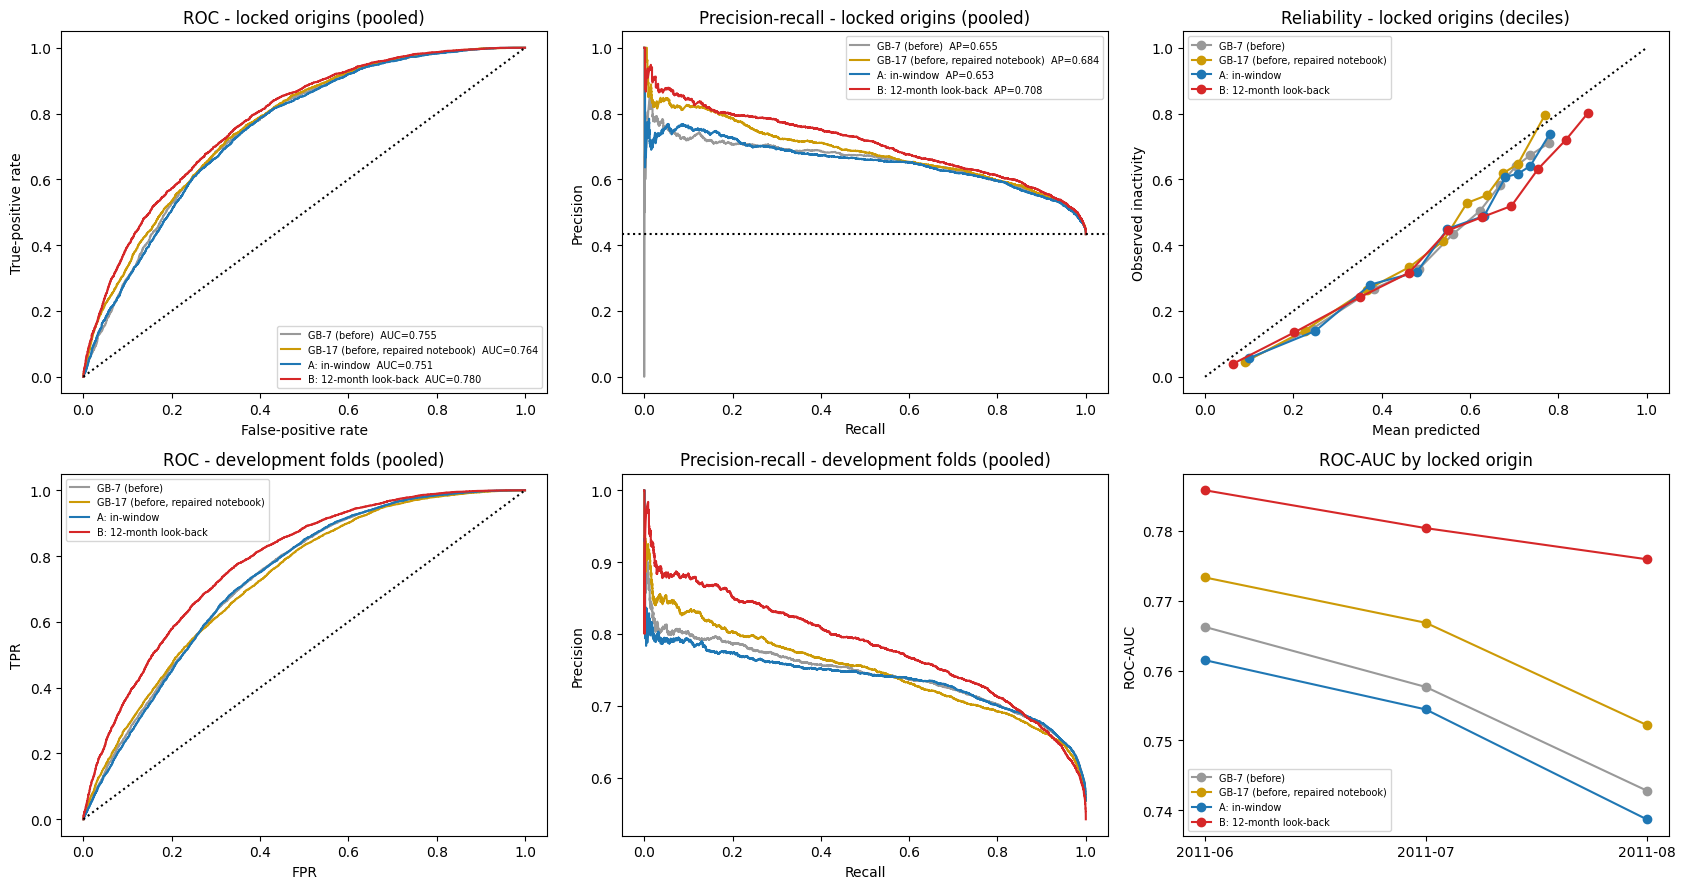

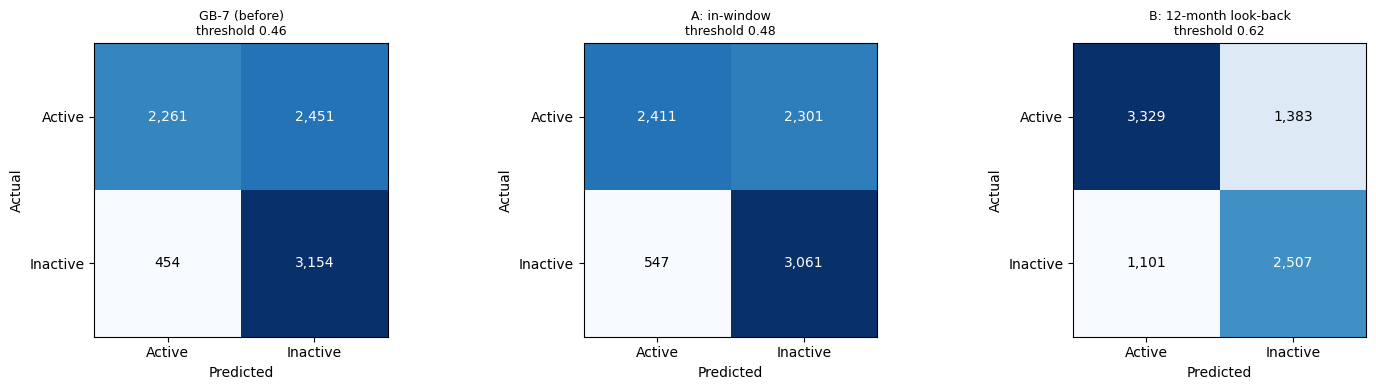

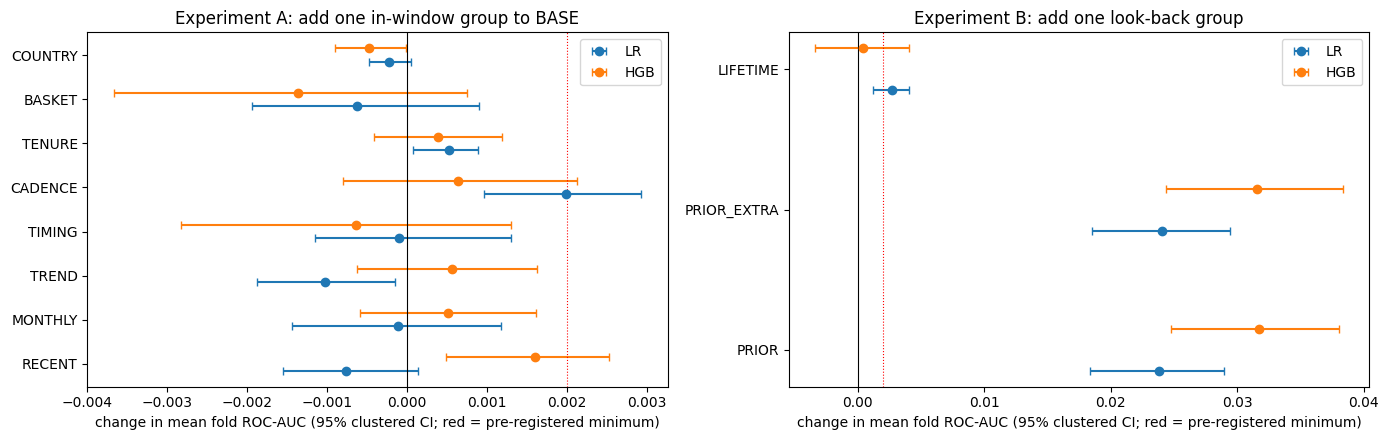

In [18]:
# 18. Curves, calibration plots, confusion matrices
colors = {"GB-7 (before)": "#999999", "GB-17 (before, repaired notebook)": "#cc9a06", "A: in-window": "#1f77b4", "B: 12-month look-back": "#d62728"}
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for name, pred in locked_pred.items():
    fpr, tpr, _ = roc_curve(pred["y"], pred["p"]); pr, rc, _ = precision_recall_curve(pred["y"], pred["p"])
    ax[0, 0].plot(fpr, tpr, color=colors[name], label=f"{name}  AUC={roc_auc_score(pred['y'], pred['p']):.3f}")
    ax[0, 1].plot(rc, pr, color=colors[name], label=f"{name}  AP={average_precision_score(pred['y'], pred['p']):.3f}")
    frac, mean_p = [], []
    edges = np.quantile(pred["p"], np.linspace(0, 1, 11)); idx = np.clip(np.searchsorted(edges, pred["p"], side="right") - 1, 0, 9)
    for b in range(10):
        m = idx == b; frac.append(pred["y"].values[m].mean()); mean_p.append(pred["p"].values[m].mean())
    ax[0, 2].plot(mean_p, frac, "o-", color=colors[name], label=name)
ax[0, 0].plot([0, 1], [0, 1], "k:"); ax[0, 0].set(title="ROC - locked origins (pooled)", xlabel="False-positive rate", ylabel="True-positive rate")
ax[0, 1].axhline(locked_pred["GB-7 (before)"]["y"].mean(), color="k", ls=":"); ax[0, 1].set(title="Precision-recall - locked origins (pooled)", xlabel="Recall", ylabel="Precision")
ax[0, 2].plot([0, 1], [0, 1], "k:"); ax[0, 2].set(title="Reliability - locked origins (deciles)", xlabel="Mean predicted", ylabel="Observed inactivity")
for a_ in ax[0]: a_.legend(fontsize=7)
for name, pred in dev_pred.items():
    fpr, tpr, _ = roc_curve(pred["y"], pred["p"]); pr, rc, _ = precision_recall_curve(pred["y"], pred["p"])
    ax[1, 0].plot(fpr, tpr, color=colors[name], label=name); ax[1, 1].plot(rc, pr, color=colors[name], label=name)
ax[1, 0].plot([0, 1], [0, 1], "k:"); ax[1, 0].set(title="ROC - development folds (pooled)", xlabel="FPR", ylabel="TPR")
ax[1, 1].set(title="Precision-recall - development folds (pooled)", xlabel="Recall", ylabel="Precision"); ax[1, 0].legend(fontsize=7)
for name in locked_pred:
    ax[1, 2].plot(per_origin.index, per_origin[name], "o-", color=colors[name], label=name)
ax[1, 2].set(title="ROC-AUC by locked origin", ylabel="ROC-AUC"); ax[1, 2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIGURE_DIR / "05_inactivity_curves_calibration.png", dpi=200, bbox_inches="tight"); plt.show()

shown = [n for n in ("GB-7 (before)", "A: in-window", "B: 12-month look-back") if n in locked_pred]
fig, axes = plt.subplots(1, len(shown), figsize=(5 * len(shown), 4))
for a_, name in zip(np.atleast_1d(axes), shown):
    r = operating[(operating["Model"] == name) & (operating["Operating point"] == "dev-selected J threshold")].iloc[0]
    cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    a_.imshow(cm, cmap="Blues"); a_.set_xticks([0, 1], ["Active", "Inactive"]); a_.set_yticks([0, 1], ["Active", "Inactive"])
    a_.set_title(f"{name}\nthreshold {J_THRESHOLD[name]:.2f}", fontsize=9); a_.set_xlabel("Predicted"); a_.set_ylabel("Actual")
    for i in range(2):
        for j in range(2): a_.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "05_inactivity_confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()

# ablation figure
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a_, (title, abl) in zip(ax, (("Experiment A: add one in-window group to BASE", ablation_A), ("Experiment B: add one look-back group", ablation_B))):
    d = abl[abl["Mode"] == "add one to base"]
    for k, fam in enumerate(ABL_FAMILIES):
        dd = d[d["Family"] == fam]; y = np.arange(len(dd)) + (k - 0.5) * 0.3
        a_.errorbar(dd["dAUC"], y, xerr=[dd["dAUC"] - dd["CI_lo"], dd["CI_hi"] - dd["dAUC"]], fmt="o", label=fam, capsize=3)
    a_.set_yticks(np.arange(len(dd)), dd["Group"]); a_.axvline(0, color="k", lw=0.8); a_.axvline(MIN_GAIN, color="r", ls=":", lw=0.8)
    a_.set(title=title, xlabel="change in mean fold ROC-AUC (95% clustered CI; red = pre-registered minimum)"); a_.legend()
plt.tight_layout(); plt.savefig(FIGURE_DIR / "05_inactivity_feature_ablation.png", dpi=200, bbox_inches="tight"); plt.show()

## 10. Before and after
All rows come from the code above. "Before" = the project's two existing models; "after" = Experiment A (in-window) and Experiment B (12-month look-back). Development-fold values for A and B are selection data and therefore optimistic; the locked-origin values are the unbiased comparison.

In [19]:
# 19. Before/after table (fixed split, development folds, locked origins)
rows = []
fx = {}
for name, s in (("GB-7 (before)", FINAL["GB-7 (before)"]), ("GB-17 (before, repaired notebook)", FINAL["GB-17 (before, repaired notebook)"]), ("A: in-window", FINAL["A: in-window"])):
    m = make_estimator(s["family"], s["params"], s["cols"]).fit(fx_train[s["cols"]], fx_train["Inactive"])
    fx[name] = (roc_auc_score(fx_val["Inactive"], m.predict_proba(fx_val[s["cols"]])[:, 1]),
                roc_auc_score(fx_hold["Inactive"], m.predict_proba(fx_hold[s["cols"]])[:, 1]))
ls = locked_summary.pivot(index="Model", columns="Scope", values="ROC_AUC")
for name in FINAL:
    rows.append({"Model": name,
                 "Fixed-split val AUC": fx.get(name, (np.nan, np.nan))[0],
                 "Rolling dev AUC (own origins)": dev_table[name].mean(),
                 "Rolling dev AUC (B origins)": dev_table.loc[[str(o) for o in DEV_B_ORIGINS], name].mean(),
                 "Confirmatory Jun-Jul AUC": ls.loc[name, "Confirmatory Jun-Jul 2011"],
                 "Aug 2011 holdout AUC (inspected)": ls.loc[name, "Previously inspected holdout Aug 2011"],
                 "Locked PR-AUC": locked_summary[(locked_summary.Model == name) & (locked_summary.Scope == "All three locked origins")]["PR_AUC"].iloc[0],
                 "Locked Brier": locked_summary[(locked_summary.Model == name) & (locked_summary.Scope == "All three locked origins")]["Brier"].iloc[0]})
before_after = pd.DataFrame(rows).set_index("Model")
display(before_after.round(4))
print("(Fixed-split AUC is not computed for B: that split trains on May-Oct 2010, where the prior window is unobservable.)")
before_after.to_csv(ARTIFACT_DIR / "inactivity_v2_before_after.csv")
locked_summary.to_csv(ARTIFACT_DIR / "inactivity_v2_locked_evaluation.csv", index=False)
locked_delta.to_csv(ARTIFACT_DIR / "inactivity_v2_locked_paired_differences.csv", index=False)
pd.concat([ablation_A.assign(Experiment="A"), ablation_B.assign(Experiment="B")]).to_csv(ARTIFACT_DIR / "inactivity_v2_feature_ablation.csv", index=False)
operating.to_csv(ARTIFACT_DIR / "inactivity_v2_operating_points.csv", index=False)
calibration.to_csv(ARTIFACT_DIR / "inactivity_v2_calibration.csv", index=False)
pd.concat([p.assign(Model=k) for k, p in locked_pred.items()]).to_csv(ARTIFACT_DIR / "inactivity_v2_locked_predictions.csv", index=False)

,Fixed-split val AUC,Rolling dev AUC (own origins),Rolling dev AUC (B origins),Confirmatory Jun-Jul AUC,Aug 2011 holdout AUC (inspected),Locked PR-AUC,Locked Brier
Model,,,,,,,
GB-7 (before),0.7450,0.7540,0.7504,0.7619,0.7428,0.6577,0.2074
"GB-17 (before, repaired notebook)",0.7595,0.7632,0.7556,0.7701,0.7522,0.6850,0.2013
A: in-window,0.7417,0.7525,0.7485,0.7580,0.7387,0.6548,0.2087
B: 12-month look-back,NaN,0.7807,0.7807,0.7831,0.7759,0.7095,0.2011


(Fixed-split AUC is not computed for B: that split trains on May-Oct 2010, where the prior window is unobservable.)


### Reading the results
* **Experiment A found no in-window improvement.** The model chosen by the pre-registered tolerance rule (simplest family within 0.002 AUC of the best) scores slightly *below* the existing 7-feature Gradient Boosting on the locked origins, with a bootstrap interval that excludes zero. The rule's tolerance cost a little accuracy; this is reported as observed and was not changed after seeing the locked data. For an in-window-only model, the existing 7-feature Gradient Boosting remains the best defensible choice.
* **The repaired notebook's 17-feature model beat the 7-feature baseline**, but the in-window ablation shows the added in-window groups do not help. Its extra look-back feature (`ObservedTenureDays`) is the plausible source; that attribution is a hypothesis, supported by its larger gain on the early development folds where look-back was available only through that feature.
* **Experiment B improves on both earlier models**, with paired intervals that exclude zero on the confirmatory snapshots and on the previously inspected holdout. Its development AUC (selection data) and locked AUC are similar, so there is no visible selection optimism. The three locked origins overlap in customers and time, so this is one body of evidence, not three replications.
* **Calibration is poor for every model on the locked origins.** Mean predicted inactivity exceeds the observed rate (negative calibration intercept) because prevalence fell relative to the training period. Experiment B's calibration slope is closest to 1 but its expected calibration error is not better, and the Brier gain is small. Use the scores as a **ranking**; do not read them as literal probabilities.
* **Risk bands use development-fold probability quantiles and do not transfer cleanly.** Live band shares differ markedly between the two models, and individual customers can land in different bands. For capacity-based targeting use the `RiskPercentile` columns.

## 11. Export for RetailPulse
Each exported bundle is trained on **all 16 labelled snapshots** (all matured labels available) using the frozen configuration, and contains: the fitted pipeline (imputation / scaling inside it), the exact ordered feature list, the cadence-prior parameters, the data start date used for the prior-window rule, risk-band cutoffs and decision threshold (both from development-fold predictions only), and metadata. Scoring goes through `src/models/inactivity_inference.py`, which calls the same feature builder used above.

Two bundles are written because the two experiments answer different questions:
* **`inactivity_model_v2.joblib`** — Experiment A, in-window features only (the protocol-compliant model).
* **`inactivity_model_v2_extended_lookback.joblib`** — Experiment B, requires transaction history for the 6 months before the observation window.

A bundle trained on all labelled data has no held-out score of its own; its expected performance is what the rolling and locked evaluations above estimate for its configuration.

In [20]:
# 20. Fit production bundles, validate schema/inference parity, write scores
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
LIVE_SNAPSHOT = pd.Period("2011-11", "M")
assert tx["InvoiceDate"].max() >= LIVE_SNAPSHOT.end_time - pd.Timedelta(days=1), "data do not reach the live snapshot"

def to_py(o):
    if isinstance(o, dict): return {k: to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o

def export_bundle(tag, spec_name, bundle_name, groups, description):
    s = FINAL[spec_name]; cols = s["cols"]
    train = TABLE.copy()
    derived = fit_derived_params(train)
    train = add_derived_features(train, derived)
    model = make_estimator(s["family"], s["params"], cols).fit(train[cols], train["Inactive"])
    dev_p = dev_pred[spec_name]["p"].values
    cutoffs = {"medium": float(np.quantile(dev_p, 0.50)), "high": float(np.quantile(dev_p, 0.80))}
    schema = [{"position": i, "name": c, "group": next(g for g, v in FEATURE_GROUPS.items() if c in v),
               "training_missing_share": float(train[c].isna().mean())} for i, c in enumerate(cols)]
    imputation = ({"strategy": "median (inside pipeline, fitted on training rows)", "values": train[cols].median().to_dict()}
                  if s["family"] in ("LR", "RF", "GB") else
                  {"strategy": "native missing-value handling in the estimator", "values": {}})
    bundle = {"model": model, "model_name": f"{s['family']} - {spec_name}", "family": s["family"], "params": s["params"],
              "experiment": tag, "description": description, "feature_groups": groups, "feature_columns": cols,
              "feature_schema": schema, "derived_params": derived, "data_start": str(DATA_START.date()),
              "imputation": imputation, "imputation_medians": train[cols].median().to_dict(),
              "target_column": "Inactive", "target_definition": "1 = no purchase in the next 3 calendar months",
              "observation_months": OBSERVATION_MONTHS, "prediction_months": PREDICTION_MONTHS,
              "decision_threshold": J_THRESHOLD[spec_name], "decision_threshold_source": "max TPR-FPR on development-fold predictions",
              "risk_band_cutoffs": cutoffs,
              "risk_band_rule": "High >= 80th percentile and Medium >= 50th percentile of development-fold predicted probabilities",
              "training": {"snapshots": [str(p) for p in sorted(train['SnapPeriod'].unique())], "rows": int(len(train)),
                           "customers": int(train["Customer ID"].nunique()), "prevalence": float(train["Inactive"].mean())},
              "evaluation": {"development_mean_auc": float(dev_table[spec_name].mean()),
                             "locked": to_py(locked_summary[locked_summary.Model == spec_name].set_index("Scope")[["ROC_AUC", "CI_lo", "CI_hi", "PR_AUC", "Brier"]].to_dict("index"))},
              "holdout_status": "Aug 2011 was inspected in earlier work and is not a pristine test set",
              "data_sha256": data_hash, "random_state": RANDOM_STATE,
              "library_versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                                   "scikit-learn": sklearn.__version__, **{k: v.__version__ for k, v in OPTIONAL.items()}},
              "created_utc": pd.Timestamp.now("UTC").isoformat()}
    joblib.dump(bundle, ARTIFACT_DIR / f"{bundle_name}.joblib")
    meta = {k: v for k, v in bundle.items() if k != "model"}
    (ARTIFACT_DIR / f"{bundle_name}_metadata.json").write_text(json.dumps(to_py(meta), indent=2, default=str))
    return bundle

bundles = {"A": export_bundle("A: in-window features only", "A: in-window", "inactivity_model_v2", A_GROUPS,
                              "Protocol-compliant model: every feature computed inside the 6-month observation window.")}
if HAVE_B:
    bundles["B"] = export_bundle("B: 12-month look-back (separate experiment)", "B: 12-month look-back",
                                 "inactivity_model_v2_extended_lookback", B_GROUPS,
                                 "Uses transactions from the 6 months before the observation window in addition to the window itself.")

# ---- validation of the exported artifacts ----
for tag, b in bundles.items():
    name = "inactivity_model_v2" if tag == "A" else "inactivity_model_v2_extended_lookback"
    loaded = load_bundle(ARTIFACT_DIR / f"{name}.joblib")                  # reload from disk
    # (1) inference parity: raw transactions -> score_snapshot == in-notebook features -> model
    inf = score_snapshot(raw, HOLDOUT_ORIGIN.end_time, loaded).set_index("Customer ID")
    ref = add_derived_features(TABLE[TABLE["SnapPeriod"] == HOLDOUT_ORIGIN], loaded["derived_params"]).set_index("Customer ID")
    ref_p = pd.Series(loaded["model"].predict_proba(ref[loaded["feature_columns"]])[:, 1], index=ref.index)
    diff = float((inf["InactivityRiskScore"] - ref_p.reindex(inf.index)).abs().max())
    assert set(inf.index) == set(ref.index) and diff < 1e-9, f"inference parity failed ({diff})"
    # (2) a frame with a missing feature must be rejected, not silently scored
    try:
        validate_feature_frame(ref.drop(columns=[loaded["feature_columns"][0]]), loaded["feature_columns"]); raise SystemExit("schema check failed to fire")
    except KeyError:
        pass
    print(f"Bundle {tag}: reload OK | inference parity max |diff| = {diff:.2e} over {len(inf):,} customers | schema guard OK | {len(loaded['feature_columns'])} features")

# ---- customer-level scores for the LIVE snapshot (no labels exist yet; uses data up to 30 Nov 2011 only) ----
live = {}
for tag, b in bundles.items():
    live[tag] = score_snapshot(raw, LIVE_SNAPSHOT.end_time, b)
    assert live[tag]["InactivityRiskScore"].between(0, 1).all() and live[tag]["InactivityRiskScore"].notna().all()
scores = live["A"].rename(columns={"InactivityRiskScore": "InactivityRiskScore_inwindow", "RiskPercentile": "RiskPercentile_inwindow", "RiskBand": "RiskBand_inwindow"})
if HAVE_B:
    scores = scores.merge(live["B"].drop(columns="Snapshot").rename(columns={"InactivityRiskScore": "InactivityRiskScore_lookback12m", "RiskPercentile": "RiskPercentile_lookback12m", "RiskBand": "RiskBand_lookback12m"}),
                          on="Customer ID", how="left", validate="one_to_one")
scores.to_csv(ARTIFACT_DIR / "inactivity_v2_customer_scores.csv", index=False)
print("\nLive-snapshot scores written for", f"{len(scores):,}", "customers; snapshot", LIVE_SNAPSHOT.end_time.date())
for tag in live:
    print(tag, live[tag]["RiskBand"].value_counts().reindex(["High", "Medium", "Low"]).to_dict())
display(scores.head(8))

(ARTIFACT_DIR / "inactivity_v2_feature_schema.json").write_text(json.dumps(
    to_py({tag: {"feature_columns": b["feature_columns"], "schema": b["feature_schema"], "derived_params": b["derived_params"],
                 "data_start": b["data_start"]} for tag, b in bundles.items()}), indent=2))
print("Artifacts in", ARTIFACT_DIR)

Bundle A: reload OK | inference parity max |diff| = 0.00e+00 over 2,813 customers | schema guard OK | 7 features


Bundle B: reload OK | inference parity max |diff| = 0.00e+00 over 2,813 customers | schema guard OK | 13 features



Live-snapshot scores written for 3,471 customers; snapshot 2011-11-30
A {'High': 710, 'Medium': 955, 'Low': 1806}
B {'High': 133, 'Medium': 851, 'Low': 2487}


,Customer ID,Snapshot,InactivityRiskScore_inwindow,RiskPercentile_inwindow,RiskBand_inwindow,InactivityRiskScore_lookback12m,RiskPercentile_lookback12m,RiskBand_lookback12m
0,13900,2011-11-30,0.878240,1.000000,High,0.562984,0.536733,Low
1,14338,2011-11-30,0.876813,0.999712,High,0.784734,0.900029,Medium
2,15658,2011-11-30,0.874840,0.999424,High,0.542619,0.508211,Low
3,16998,2011-11-30,0.870862,0.999136,High,0.674467,0.707289,Low
4,18037,2011-11-30,0.865456,0.998848,High,0.598246,0.582541,Low
5,14792,2011-11-30,0.855936,0.998559,High,0.830881,0.954192,Medium
6,18268,2011-11-30,0.855071,0.998271,High,0.744504,0.830020,Medium
7,13307,2011-11-30,0.852622,0.997983,High,0.782900,0.897724,Medium


Artifacts in /tmp/rp/artifacts/inactivity


In [21]:
# 21. Write a plain-text results report from the executed tables
def block(title, df, nd=4):
    return f"## {title}\n\n```\n{df.round(nd).to_string()}\n```\n"
report = ["# Inactivity prediction v2 - executed results\n",
          f"Generated by `notebooks/05_inactivity_prediction_final.ipynb` on {pd.Timestamp.now('UTC'):%Y-%m-%d %H:%M} UTC. "
          "All values are computed by the notebook; nothing is hand-entered.\n",
          "Roles: development folds Dec 2010-May 2011 (selection data); confirmatory Jun-Jul 2011; Aug 2011 is a **previously inspected holdout, not pristine**.\n",
          block("Before / after", before_after), block("Locked evaluation (ROC-AUC with clustered 95% CI)", locked_summary),
          block("Paired AUC differences", locked_delta), block("Experiment A ablation", ablation_A), block("Experiment B ablation", ablation_B),
          block("Operating points (locked origins)", operating, 3), block("Calibration (locked origins)", calibration, 3),
          block("Fixed-split reproduction of the previous results", fixed_split_before)]
(DOC_DIR / "05_inactivity_final_results.md").write_text("\n".join(report))
print("Wrote", DOC_DIR / "05_inactivity_final_results.md")

Wrote /tmp/rp/docs/inactivity/05_inactivity_final_results.md


## 12. Limitations (these apply regardless of the results above)
* One online retailer, ~2 years, ~5,200 customers; the three locked origins overlap in customers and label windows, so they are not independent replications.
* The Aug 2011 holdout was inspected earlier and is reported as such. Jun/Jul 2011 were not evaluated before, but they share customers and time with Aug 2011.
* Predicted probabilities follow the calendar-driven base rate (prevalence moves strongly between months). Use them primarily as a **ranking**; risk bands and thresholds are derived from development-fold predictions and may need re-basing when prevalence shifts. See the calibration table.
* Anonymous purchases (no Customer ID) are invisible, so "inactive" means "no identified purchase".
* Seasonal (month-of-year) effects cannot be learned or validated with fewer than two years of history; they were deliberately not modelled.
* Experiment B depends on the data starting in Dec 2009: only snapshots from Nov 2010 can learn the prior-window feature, so its training evidence is thinner than Experiment A's.
* Predictive association is not causal; a high inactivity score does not show that a campaign would change behaviour.